In [1]:
# Compute and compare CLIP embeddings of image–text pairs

In [13]:
import numpy as np
import open_clip
import torch
import umap.plot
from PIL import Image

In [2]:
model, _, preprocess = open_clip.create_model_and_transforms('ViT-B-32', pretrained='laion2b_s34b_b79k')
model.eval()  # model in train mode by default, impacts some models with BatchNorm or stochastic depth active
tokenizer = open_clip.get_tokenizer('ViT-B-32')


In [7]:
# Example from open CLIP doc
image = preprocess(Image.open("img/CLIP.png")).unsqueeze(0)
text = tokenizer(["a diagram", "a dog", "a cat"])

with torch.no_grad():
    image_features = model.encode_image(image)
    text_features = model.encode_text(text)
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)

print("Label probs:", text_probs)
print("The image most likely is \"a diagram\"")

Label probs: tensor([[9.9951e-01, 4.0415e-04, 8.4107e-05]])
The image most likely is "a diagram"


In [39]:
labels = []
samples = []
datasets = ["nouns", "verbs"]
for file in datasets:
    with open(f"res/{file}", "r") as f:
        content = f.read().splitlines()
        samples.extend(content)
        labels.extend([file] * len(content))

#print(samples)
#print(labels)

['apple', 'banana', 'orange', 'lemon', 'strawberry', 'grape', 'watermelon', 'peach', 'pear', 'pineapple', 'carrot', 'potato', 'tomato', 'broccoli', 'mushroom', 'pumpkin', 'onion', 'cucumber', 'pepper', 'corn', 'dog', 'cat', 'horse', 'cow', 'sheep', 'goat', 'pig', 'rabbit', 'deer', 'fox', 'lion', 'tiger', 'bear', 'wolf', 'elephant', 'giraffe', 'zebra', 'monkey', 'panda', 'kangaroo', 'eagle', 'owl', 'parrot', 'penguin', 'sparrow', 'flamingo', 'swan', 'peacock', 'duck', 'chicken', 'chair', 'table', 'desk', 'sofa', 'bed', 'lamp', 'mirror', 'shelf', 'cabinet', 'stool', 'book', 'pencil', 'notebook', 'camera', 'phone', 'clock', 'key', 'bottle', 'cup', 'plate', 'bicycle', 'car', 'truck', 'bus', 'train', 'airplane', 'boat', 'scooter', 'tractor', 'motorcycle', 'mountain', 'river', 'ocean', 'forest', 'desert', 'island', 'waterfall', 'volcano', 'meadow', 'glacier', 'castle', 'bridge', 'lighthouse', 'temple', 'tower', 'cabin', 'stadium', 'museum', 'factory', 'greenhouse', 'run', 'walk', 'jump', 'cr

<Axes: >

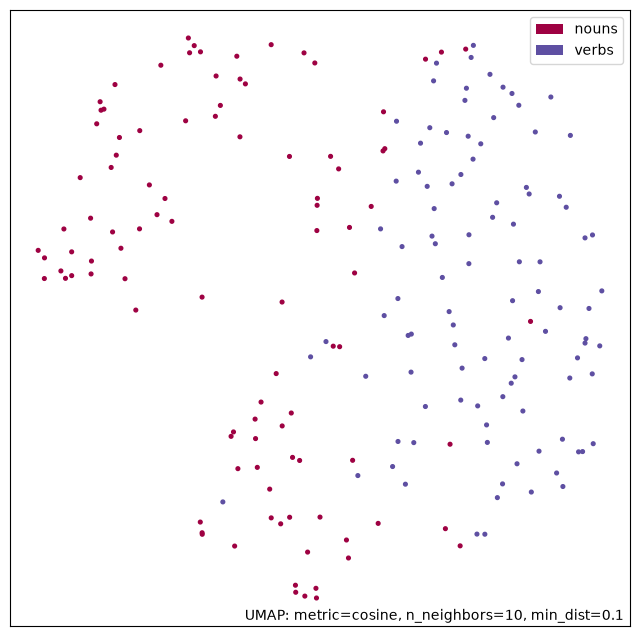

In [40]:
text = tokenizer(samples)

with torch.no_grad():
    text_features = model.encode_text(text)

example = umap.UMAP(
    n_neighbors=10, n_components=2, metric="cosine").fit(text_features)
umap.plot.points(example, labels=np.array(labels))
